# MLP

**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These tutorials use a CPU and the full original SIRDS bank. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `7a0813987944`](https://github.com/OJWatson/metis/tree/7a081398794492c82d92812b5801900f62f8639a).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Short uv setup cell shared by downloadable notebooks."""

import os
from pathlib import Path
import re
import shlex
import subprocess
import sys


def prepare_colab(revision):
    """Use the checkout's locked environment in Colab's active interpreter."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    if not (os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION")):
        print("Using your local METIS environment.")
        return
    # The source commit matches the results saved in this notebook.
    source = Path("/content/metis-tutorial")
    commands = f'''
set -euo pipefail
export PATH="$HOME/.local/bin:$PATH"
command -v uv >/dev/null || curl -LsSf https://astral.sh/uv/0.7.22/install.sh | sh
[ -d {source}/.git ] || git clone -q https://github.com/OJWatson/metis.git {source}
git -C {source} fetch -q origin {revision}
git -C {source} checkout -q --detach {revision}
uv sync --project {source} --python {shlex.quote(sys.executable)} --locked --inexact --no-dev --extra docs --no-editable
'''
    subprocess.run(
        ["bash", "-c", commands], check=True,
        env={**os.environ, "UV_PROJECT_ENVIRONMENT": sys.prefix, "UV_NO_MODIFY_PATH": "1"},
    )
    print("METIS is ready. If Colab reports a library-version conflict or asks for a restart, restart the session, then Run all.")


prepare_colab("7a081398794492c82d92812b5801900f62f8639a")


The MLP (MultiLayer Perceptron) or *feedforward neural network* is METIS's most basic architecture.

## When this might be a good fit

The MLP is a good starting point for datasets with only static inputs. It is very fast to train and generate predictions from. Unlike the Normalising Flow or Flow Matching architectures, the MLP is a deterministic surrogate. Compare validation performance before choosing a more complex model.


## How does an MLP work?

### Architectural walkthrough
An MLP's computation is a series of matrix multiplications composed with non-linear activations. METIS's implementation also includes *residual* connections which stabilise the training of deeper networks.

In order to get a better sense of how these components work let's trace through the network's forward computation:


```python
x = self.input_layer(inputs)
for block in self.blocks:
    x = block(x)
x = self.output_layer(x)
```

The input_layer linearly projects (i.e. a matrix multiplication) the static input vector to vectors the size of the model's hidden dimension. Next, we iteratively pass our transformed inputs through a series of residual blocks.

Each residual block applies several layers to the input and adds the result back to the original input:

![Residual block structure.](https://ojwatson.github.io/metis/models/images/residual-block.png)

Finally, the output layer linearly projects `x` to the output dimensionality.

### Training
The MLP is trained to minimise the mean squared error between standardized predictions and simulations:

$$
\mathrm{Loss} = \frac{1}{M}\sum_{m=1}^{M}(\mathrm{MLP}^{\theta}(\mathrm{static\_input}_m)-\mathrm{output}_m)^2
$$

## Configuring an MLP

Pass architecture options to `Surrogate("mlp", model_options={...})`:

| Option | Meaning | Default |
|---|---|---:|
| `hidden_dim` | Width of the hidden layers | 64 |
| `num_blocks` | Number of residual blocks | 2 |
| `num_layers_per_block` | Layers in each residual block | 2 |

Input and output dimensions are inferred from the simulation bank. The same
options can be set through [Hydra](https://ojwatson.github.io/metis/basics/hydra.html):

```bash
uv run metis train model=mlp model.model_options.hidden_dim=128
```

## Training on SIRDS

We use the full [SIRDS bank](https://ojwatson.github.io/metis/basics/sirds-example.html): 1,000 parameter
settings, five realisations per setting and all 200 daily outputs. The grouped
split matches the [training tutorial](https://ojwatson.github.io/metis/basics/training.html): 600 settings for
training, 200 for validation and 200 for testing. This CPU fit uses 1,000
optimizer steps.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from metis import load_example, Surrogate, TrainingConfig

bank = load_example()
split = bank.split(seed=42)

In [2]:
model = Surrogate(
    "mlp",
    model_options={"hidden_dim": 64, "num_blocks": 2, "num_layers_per_block": 2},
).fit(
    split.train, split.validation,
    config=TrainingConfig(steps=1000, batch_size=64, eval_every=100, seed=42),
)

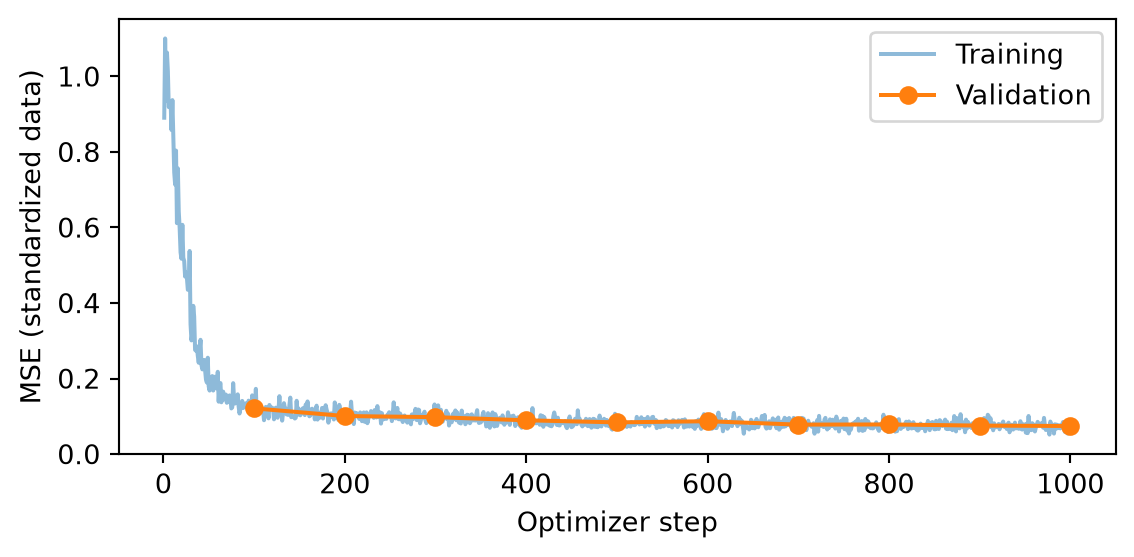

In [3]:
#| code-fold: true
#| code-summary: "Plot training and validation loss"
#| fig-cap: "MLP: loss on the full SIRDS bank: 600 training settings and 200 validation settings."
validation = [row for row in model.history if "validation_loss" in row]
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot([row["step"] for row in model.history],
        [row["train_loss"] for row in model.history], alpha=0.5, label="Training")
ax.plot([row["step"] for row in validation],
        [row["validation_loss"] for row in validation], "o-", label="Validation")
ax.set(xlabel="Optimizer step", ylabel="MSE (standardized data)")
ax.legend()
fig.tight_layout()
plt.show()

*MLP: loss on the full SIRDS bank: 600 training settings and 200 validation settings.*

Predict an entire trajectory at the first held-out parameter setting. A
deterministic prediction aims to capture the conditional average, whereas the
simulator produces different realisations at the same inputs.

In [4]:
inputs = split.test.inputs[:1]
prediction = model.predict(inputs)[0]
print("Predicted times × outputs:", prediction.shape)

Predicted times × outputs: (200, 4)


/home/runner/work/metis/metis/src/metis/surrogate.py:672: UserWarning: Inputs outside the training ranges for ['I_0']; predictions extrapolate and are not clipped.
  array = self._inputs(inputs)


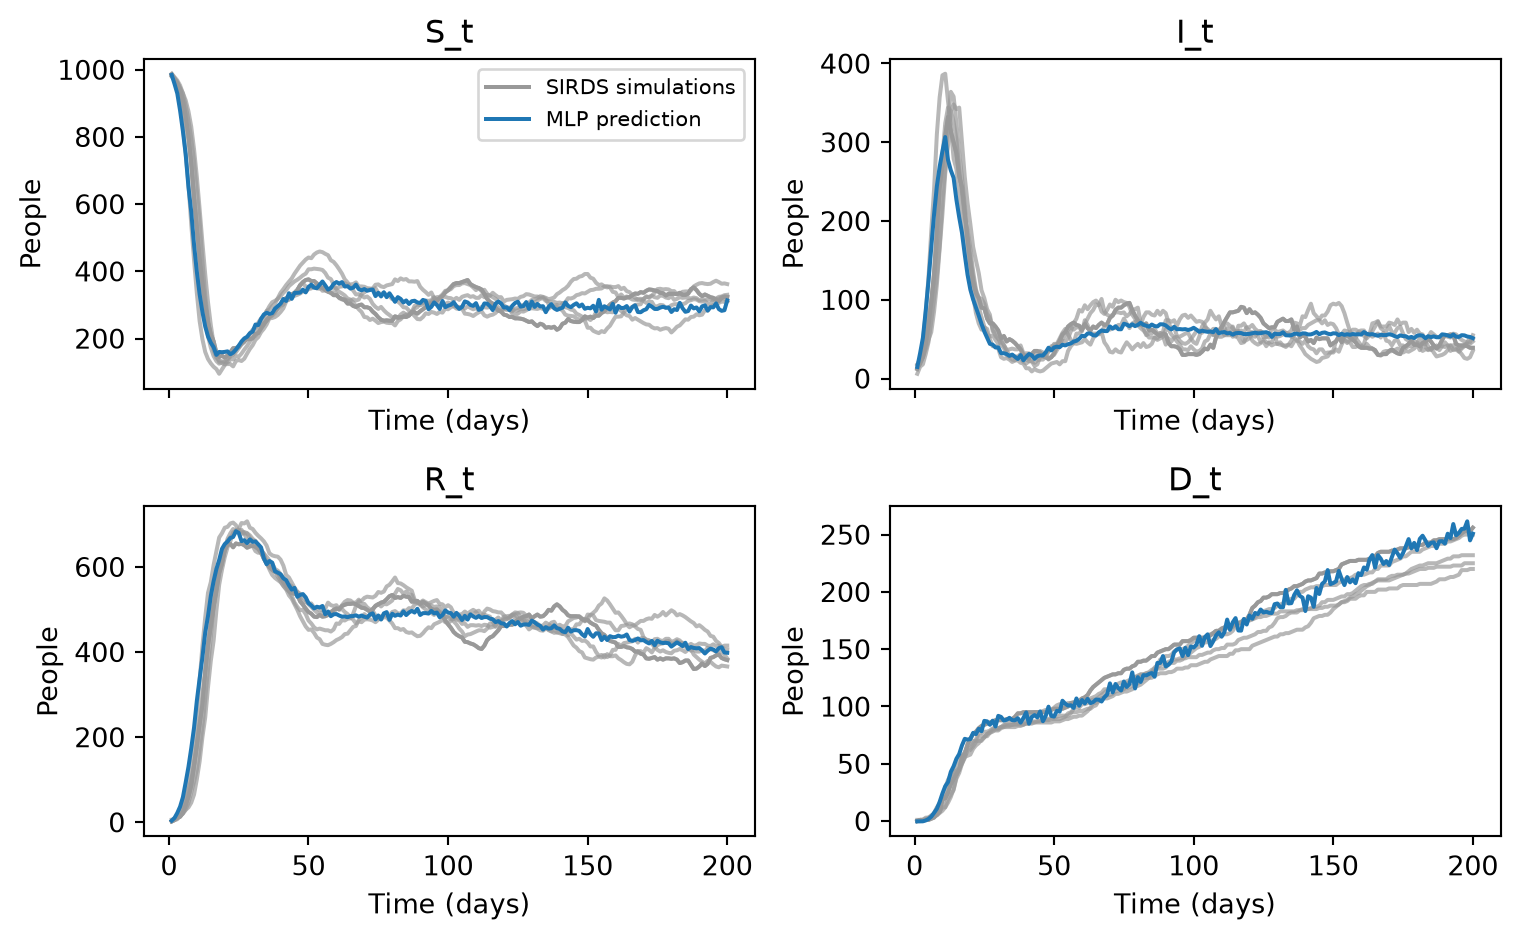

In [5]:
#| code-fold: true
#| code-summary: "Compare the prediction with SIRDS simulations"
#| fig-cap: "MLP: prediction and five SIRDS simulations at the first held-out parameter setting. The model was fitted to 600 settings from the full 200-day SIRDS bank."
same_inputs = np.all(split.test.inputs == inputs[0], axis=1)
replicates = split.test.outputs[same_inputs]
fig, axes = plt.subplots(2, 2, figsize=(8, 5), sharex=True)
for channel, ax in enumerate(axes.flat):
    ax.plot(bank.times, replicates[:, :, channel].T, color="0.6", alpha=0.7)
    ax.plot(bank.times, replicates[0, :, channel], color="0.6", label="SIRDS simulations")
    ax.plot(bank.times, prediction[:, channel], color="C0", label="MLP prediction")
    ax.set(title=bank.output_names[channel], xlabel="Time (days)", ylabel="People")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()

*MLP: prediction and five SIRDS simulations at the first held-out parameter setting. The model was fitted to 600 settings from the full 200-day SIRDS bank.*

Compare predictions over the whole held-out bank, not just one setting; the
[training tutorial](https://ojwatson.github.io/metis/basics/training.html) shows how to evaluate the fit.